# 02 R-GCN and GNNExplainer

Train or load an R-GCN for knowledge graph node classification, evaluate predictive performance, and generate local explanations with GNNExplainer.

## 1. Setup

Import the libraries, set random seeds, and define the local data files used throughout the notebook.


#### 1.1 Import Libraries

In [47]:
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import rdflib as rdf
import torch
import torch.nn.functional as F
from rdflib import Literal, URIRef
from sklearn.metrics import classification_report, confusion_matrix
from torch_geometric.data import Data
from torch_geometric.explain import Explainer, GNNExplainer
from torch_geometric.nn import FastRGCNConv

from graph_llm_explainer import (
    build_model_triples,
    build_relation_vocabulary,
    model_excluded_predicates,
)

#### 1.2 Set Random Seeds

In [48]:
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

#### 1.3 Configure Notebook

In [49]:
TRAIN_MODEL = True
EXPLAIN_TOP_K = 10

device = torch.device("mps" if torch.mps.is_available() else "cpu")

device

device(type='mps')

In [50]:
# Locate the project root relative to the working directory
PROJECT_ROOT = Path(".")

if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = Path("..")

# Project directories
DATA_DIR = PROJECT_ROOT / "data" / "raw"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
RESULTS_DIR = PROJECT_ROOT / "results"
EXPLANATIONS_DIR = RESULTS_DIR / "explanations"

# Dataset files
RDF_PATH = DATA_DIR / "aifbfixed_complete.n3"
COMPLETE_LABELS_PATH = DATA_DIR / "completeDataset.tsv"
TRAIN_LABELS_PATH = DATA_DIR / "trainingSet.tsv"
TEST_LABELS_PATH = DATA_DIR / "testSet.tsv"

# Model checkpoint
MODEL_CHECKPOINT_PATH = ARTIFACT_DIR / "rgcn_baseline.pt"

# Explanation output files
EXPLANATION_JSON_TEMPLATE = "gnnexplainer_node_{node_id}.json"
EXPLANATION_EDGES_TEMPLATE = "gnnexplainer_node_{node_id}_edges.csv"

# Verify required files and directories
required_paths = {
    "RDF graph": RDF_PATH,
    "Complete labels": COMPLETE_LABELS_PATH,
    "Training split": TRAIN_LABELS_PATH,
    "Test split": TEST_LABELS_PATH,
    "Artifacts": ARTIFACT_DIR,
    "Explanations": EXPLANATIONS_DIR,
}

for name, path in required_paths.items():
    print(f"{name:<18} {path.exists()}  {path}")

RDF graph          True  ../data/raw/aifbfixed_complete.n3
Complete labels    True  ../data/raw/completeDataset.tsv
Training split     True  ../data/raw/trainingSet.tsv
Test split         True  ../data/raw/testSet.tsv
Artifacts          True  ../artifacts
Explanations       True  ../results/explanations


## 2. Load and Encode the RDF Graph

Convert the RDF knowledge graph into the tensor representation required by the R-GCN. The target-label relation is removed before encoding to prevent label leakage.

#### 2.1 Load RDF Graph and Remove Target Relation

To prevent target leakage, the target predicate swrc:affiliation was removed from the model graph. Additional analysis showed that swrc:member partially encoded the same affiliation information for a subset of labelled researchers. Therefore, swrc:member and swrc:employs were also excluded in the final setup. This reduced the risk of shortcut learning while maintaining comparable predictive performance.

In [51]:
# Load the complete RDF knowledge graph
g = rdf.Graph()
g.parse(RDF_PATH, format="n3")

# Remove target-label relations to prevent label leakage
SWRC = "http://swrc.ontoware.org/ontology#"

EXCLUDE_MEMBER = True
EXCLUDE_EMPLOYS = True

TARGET_PREDICATES_TO_EXCLUDE = model_excluded_predicates(
    exclude_member=EXCLUDE_MEMBER,
    exclude_employs=EXCLUDE_EMPLOYS,
)

model_triples = build_model_triples(g, TARGET_PREDICATES_TO_EXCLUDE)

graph_loading_summary = pd.Series(
    {
        "Original RDF triples": len(g),
        "Model RDF triples": len(model_triples),
        "Removed RDF triples": len(g) - len(model_triples),
    },
    name="value",
).to_frame()

graph_loading_summary

,value
Original RDF triples,29226
Model RDF triples,28704
Removed RDF triples,522


#### 2.2 Build Node and Relation Mappings

In [52]:
# Create a stable relation vocabulary from the model graph
relations = build_relation_vocabulary(model_triples)

# Keep all RDF nodes so node IDs remain aligned with the complete graph
nodes = sorted(
    set(g.subjects()).union(g.objects()),
    key=str,
)

relations_dict = {relation: idx for idx, relation in enumerate(relations)}

nodes_dict = {str(node): idx for idx, node in enumerate(nodes)}

# Reverse mappings are needed for decoding explanations later
inv_nodes_dict = {idx: node for node, idx in nodes_dict.items()}

inv_relations_dict = {idx: relation for relation, idx in relations_dict.items()}

#### 2.3 Create Forward and Inverse Edges

In [53]:
# Encode RDF triples as directed edges with relation-specific edge types
edges = []

for subject, predicate, obj in model_triples:
    source_id = nodes_dict[str(subject)]
    target_id = nodes_dict[str(obj)]
    relation_id = relations_dict[predicate]

    # Forward edge: original RDF direction
    edges.append((source_id, target_id, 2 * relation_id))

    # Inverse edge: enables bidirectional message passing
    edges.append((target_id, source_id, 2 * relation_id + 1))

#### 2.4 Convert Edges to PyTorch Geometric Tensors

In [54]:
edge = (
    torch.tensor(
        edges,
        dtype=torch.long,
    )
    .t()
    .contiguous()
)

edge_index = edge[:2]
edge_type = edge[2]

num_nodes = len(nodes)
num_relations = 2 * len(relations)

#### 2.5 Summarize Encoded Graph Representation

In [55]:
graph_encoding_summary = pd.Series(
    {
        "Nodes": num_nodes,
        "RDF relation types": len(relations),
        "Edge types (with inverse)": num_relations,
        "Directed edges": edge_index.size(1),
    },
    name="value",
).to_frame()

graph_encoding_summary

,value
Nodes,8285
RDF relation types,44
Edge types (with inverse),88
Directed edges,57408


## 3. Build Node Features

The AIFB dataset does not provide numerical node attributes. Therefore, each node is represented by a simple structural feature: its outgoing degree in the encoded graph. The degree values are one-hot encoded and used as the input feature matrix for the R-GCN.



#### 3.1 Compute Node Degrees

In [56]:
# Count outgoing edges per node
source_degree = torch.bincount(
    edge_index[0],
    minlength=num_nodes,
)

#### 3.2 Encode Degree Values

In [57]:
# Map each observed degree value to a feature index
active_degrees = torch.unique(source_degree).sort().values

degree_to_feature = {
    int(degree): idx for idx, degree in enumerate(active_degrees.tolist())
}

feature_ids = torch.tensor(
    [degree_to_feature[int(degree)] for degree in source_degree.tolist()],
    dtype=torch.long,
)

#### 3.3 Create Feature Matrix

In [58]:
# One-hot encode node degrees as structural node features
x = F.one_hot(
    feature_ids,
    num_classes=len(active_degrees),
).float()

feature_names = [f"degree_{int(degree):04d}" for degree in active_degrees.tolist()]

in_channels = x.size(1)

#### 3.4 Summarize Node Features

In [59]:
node_feature_summary = pd.Series(
    {
        "Feature matrix shape": str(tuple(x.shape)),
        "Active degree features": len(feature_names),
        "Minimum degree": int(source_degree.min()),
        "Maximum degree": int(source_degree.max()),
        "Input channels": in_channels,
    },
    name="value",
).to_frame()

node_feature_summary

,value
Feature matrix shape,"(8285, 125)"
Active degree features,125
Minimum degree,0
Maximum degree,1247
Input channels,125


## 4. Load Labels and Train/Test Splits

The label files define the supervised node classification task. The R-GCN uses the full graph for message passing, but only the training labels are used for optimization.

#### 4.1 Load Label Tables

In [60]:
label_header = "label_affiliation"
node_header = "person"

labels_df = pd.read_csv(COMPLETE_LABELS_PATH, sep="\t")
train_labels_df = pd.read_csv(TRAIN_LABELS_PATH, sep="\t")
test_labels_df = pd.read_csv(TEST_LABELS_PATH, sep="\t")

#### 4.2 Encode Class Labels

In [61]:
# Map affiliation URIs to integer class IDs
labels = sorted(labels_df[label_header].unique())

labels_dict = {label: idx for idx, label in enumerate(labels)}

inv_labels_dict = {idx: label for label, idx in labels_dict.items()}

num_classes = len(labels)

#### 4.3 Convert Splits to Tensors

In [62]:
# Convert labelled node URIs and affiliation labels to tensor format
train_idx = torch.tensor(
    [nodes_dict[node] for node in train_labels_df[node_header]],
    dtype=torch.long,
)

train_y = torch.tensor(
    [labels_dict[label] for label in train_labels_df[label_header]],
    dtype=torch.long,
)

test_idx = torch.tensor(
    [nodes_dict[node] for node in test_labels_df[node_header]],
    dtype=torch.long,
)

test_y = torch.tensor(
    [labels_dict[label] for label in test_labels_df[label_header]],
    dtype=torch.long,
)

#### 4.4 Validate Label Encoding

In [63]:
label_encoding_summary = pd.Series(
    {
        "Labelled nodes": len(labels_df),
        "Training nodes": train_idx.numel(),
        "Test nodes": test_idx.numel(),
        "Classes": num_classes,
        "All labelled nodes in graph": labels_df[node_header].isin(nodes_dict).all(),
    },
    name="value",
).to_frame()

label_encoding_summary

,value
Labelled nodes,176
Training nodes,140
Test nodes,36
Classes,4
All labelled nodes in graph,True


#### 4.5 Compare Split Distributions

In [64]:
# Compare class distributions across train and test splits
split_distribution = pd.concat(
    [
        train_labels_df.assign(split="train"),
        test_labels_df.assign(split="test"),
    ],
    ignore_index=True,
)

split_distribution = (
    split_distribution.groupby(["split", label_header])
    .size()
    .rename("count")
    .reset_index()
)

split_distribution[label_header] = split_distribution[label_header].map(labels_dict)

split_distribution = split_distribution.rename(
    columns={label_header: "label_id"}
).sort_values(["split", "label_id"])

split_distribution

,split,label_id,count
0,test,0,15
1,test,1,6
2,test,2,12
3,test,3,3
4,train,0,58
5,train,1,22
6,train,2,48
7,train,3,12


## 5. Create the PyTorch Geometric Data Object

Combine node features, graph structure, and train/test labels into a single `Data` object that serves as the input to the R-GCN.

In [65]:
# Bundle graph structure, node features, and labels into a single PyTorch Geometric Data object
data = Data(
    x=x,
    edge_index=edge_index,
    edge_type=edge_type,
    train_idx=train_idx,
    train_y=train_y,
    test_idx=test_idx,
    test_y=test_y,
    num_nodes=num_nodes,
).to(device)

# Move the graph data to the selected device
data

Data(x=[8285, 125], edge_index=[2, 57408], edge_type=[57408], train_idx=[140], train_y=[140], test_idx=[36], test_y=[36], num_nodes=8285)

## 6. Define the R-GCN Model

A compact two-layer R-GCN is used for node classification. The first layer learns hidden node representations from the relational graph structure, while the second layer maps these representations to the affiliation classes.

In [66]:
class RGCN(torch.nn.Module):
    """Two-layer R-GCN for knowledge graph node classification."""

    def __init__(
        self,
        in_channels: int,
        hidden_channels: int,
        out_channels: int,
        num_relations: int,
    ):
        super().__init__()

        # Reduce parameters for graphs with many relation types
        num_bases = min(30, num_relations)

        self.conv1 = FastRGCNConv(
            in_channels,
            hidden_channels,
            num_relations,
            num_bases=num_bases,
        )

        self.conv2 = FastRGCNConv(
            hidden_channels,
            out_channels,
            num_relations,
            num_bases=num_bases,
        )

    def forward(self, x, edge_index, edge_type):
        x = self.conv1(x, edge_index, edge_type).relu()
        x = F.dropout(x, p=0.2, training=self.training)
        x = self.conv2(x, edge_index, edge_type)

        return F.log_softmax(x, dim=-1)

#### 6.1 Initialize Model and Optimizer

In [67]:
HIDDEN_CHANNELS = 16

model = RGCN(
    in_channels=in_channels,
    hidden_channels=HIDDEN_CHANNELS,
    out_channels=num_classes,
    num_relations=num_relations,
).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=5e-4,
)

model

RGCN(
  (conv1): FastRGCNConv(125, 16, num_relations=88)
  (conv2): FastRGCNConv(16, 4, num_relations=88)
)

## 7. Train or Load the Model

The model can either be trained from scratch or loaded from a saved checkpoint. When loading a checkpoint, the stored metadata is checked against the current graph and model configuration to avoid using incompatible parameters.

#### 7.1 Define Training and Evaluation Functions

In [68]:
def train_one_epoch():
    """Run one optimization step on the labelled training nodes."""
    model.train()
    optimizer.zero_grad()

    out = model(data.x, data.edge_index, data.edge_type)

    # Compute loss only on labelled training nodes
    loss = F.nll_loss(
        out[data.train_idx],
        data.train_y,
    )

    loss.backward()
    optimizer.step()

    return float(loss.detach().cpu())


@torch.no_grad()
def evaluate():
    """Evaluate train and test accuracy without updating model parameters."""
    model.eval()

    out = model(data.x, data.edge_index, data.edge_type)
    pred = out.argmax(dim=-1)

    train_acc = (pred[data.train_idx] == data.train_y).float().mean().item()

    test_acc = (pred[data.test_idx] == data.test_y).float().mean().item()

    return train_acc, test_acc, pred.cpu()

#### 7.2 Define Checkpoint Utilities

In [69]:
def checkpoint_metadata():
    """Store graph and model settings required for checkpoint compatibility."""
    return {
        "in_channels": in_channels,
        "hidden_channels": HIDDEN_CHANNELS,
        "num_classes": num_classes,
        "num_relations": num_relations,
        "labels": labels,
        "excluded_predicates": [
            str(predicate) for predicate in TARGET_PREDICATES_TO_EXCLUDE
        ],
    }


def load_checkpoint(path):
    """Load a checkpoint only if it matches the current model configuration."""
    checkpoint = torch.load(
        path,
        map_location=device,
    )

    metadata = checkpoint.get("metadata", {})
    expected = checkpoint_metadata()

    keys_to_check = [
        "in_channels",
        "hidden_channels",
        "num_classes",
        "num_relations",
    ]

    mismatches = {
        key: (metadata.get(key), expected[key])
        for key in keys_to_check
        if metadata.get(key) != expected[key]
    }

    if mismatches:
        raise ValueError(
            f"Checkpoint does not match current graph/model setup: {mismatches}"
        )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    return metadata

#### 7.3 Train or Load Checkpoint

In [70]:
if TRAIN_MODEL or not MODEL_CHECKPOINT_PATH.exists():
    history = []
    start = time.time()

    for epoch in range(1, 51):
        loss = train_one_epoch()
        train_acc, test_acc, _ = evaluate()

        history.append(
            {
                "epoch": epoch,
                "loss": loss,
                "train_acc": train_acc,
                "test_acc": test_acc,
            }
        )

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Epoch {epoch:02d} | "
                f"loss={loss:.4f} | "
                f"train={train_acc:.4f} | "
                f"test={test_acc:.4f}"
            )

    training_time = time.time() - start
    history_df = pd.DataFrame(history)

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "metadata": checkpoint_metadata(),
        },
        MODEL_CHECKPOINT_PATH,
    )

    print(f"Training time: {training_time:.2f}s")
    print(f"Saved checkpoint to {MODEL_CHECKPOINT_PATH}")

    display(history_df.tail())

else:
    metadata = load_checkpoint(MODEL_CHECKPOINT_PATH)
    history_df = pd.DataFrame()

    print(f"Loaded checkpoint from {MODEL_CHECKPOINT_PATH}")

Epoch 01 | loss=1.3575 | train=0.6714 | test=0.5833
Epoch 05 | loss=0.3787 | train=0.9429 | test=0.8889
Epoch 10 | loss=0.1128 | train=0.9643 | test=0.9167
Epoch 15 | loss=0.0827 | train=0.9786 | test=0.9444
Epoch 20 | loss=0.0453 | train=0.9857 | test=0.9722
Epoch 25 | loss=0.0541 | train=0.9857 | test=0.9722
Epoch 30 | loss=0.0415 | train=0.9857 | test=0.9722
Epoch 35 | loss=0.0439 | train=0.9857 | test=0.9722
Epoch 40 | loss=0.0340 | train=0.9857 | test=0.9722
Epoch 45 | loss=0.0487 | train=0.9857 | test=0.9444
Epoch 50 | loss=0.0456 | train=0.9857 | test=0.9444
Training time: 17.32s
Saved checkpoint to ../artifacts/rgcn_baseline.pt


,epoch,loss,train_acc,test_acc
45,46,0.066792,0.985714,0.944444
46,47,0.050666,0.985714,0.944444
47,48,0.053431,0.985714,0.944444
48,49,0.051560,0.985714,0.944444
49,50,0.045560,0.985714,0.944444


## 8. Evaluate the R-GCN

Evaluate the trained R-GCN on the held-out test nodes. The evaluation includes overall accuracy, class-wise metrics, and a confusion matrix.

#### 8.1 Compute Predictions

In [71]:
# Evaluate model and extract test predictions
train_acc, test_acc, pred = evaluate()

y_true = data.test_y.cpu().numpy()
y_pred = pred[data.test_idx.cpu()].numpy()

#### 8.2 Summarize Overall Performance

In [72]:
evaluation_summary = pd.Series(
    {
        "Final train accuracy": train_acc,
        "Final test accuracy": test_acc,
        "Test nodes": len(y_true),
    },
    name="value",
).to_frame()

evaluation_summary

,value
Final train accuracy,0.985714
Final test accuracy,0.944444
Test nodes,36.000000


#### 8.3 Compute Class-wise Metrics

In [73]:
target_names = [f"class_{idx}" for idx in range(num_classes)]

print(
    classification_report(
        y_true,
        y_pred,
        target_names=target_names,
        zero_division=0,
    )
)

              precision    recall  f1-score   support

     class_0       0.94      1.00      0.97        15
     class_1       1.00      0.83      0.91         6
     class_2       1.00      1.00      1.00        12
     class_3       0.67      0.67      0.67         3

    accuracy                           0.94        36
   macro avg       0.90      0.88      0.89        36
weighted avg       0.95      0.94      0.94        36



#### 8.4 Analyze Prediction Errors

In [74]:
# Build confusion matrix for class-specific error analysis
confusion = pd.DataFrame(
    confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(num_classes)),
    ),
    index=[f"Class {idx}" for idx in range(num_classes)],
    columns=[f"Class {idx}" for idx in range(num_classes)],
)

confusion

,Class 0,Class 1,Class 2,Class 3
Class 0,15,0,0,0
Class 1,0,5,0,1
Class 2,0,0,12,0
Class 3,1,0,0,2


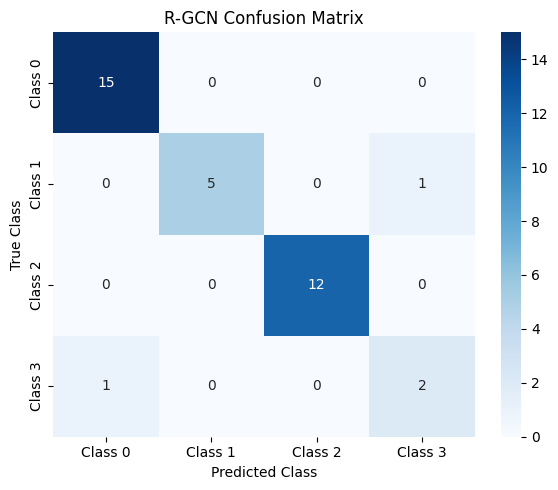

In [75]:
# Visualize the confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    ax=ax,
)

ax.set_title("R-GCN Confusion Matrix")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")

plt.tight_layout()
plt.show()

## 9. Inspect Individual Predictions

The numeric predictions are converted back to affiliation labels and combined with the corresponding test nodes. This table is used for node-level error analysis and for selecting an instance for local explanation.

In [76]:
# Create node-level prediction table for the test set
test_predictions = pd.DataFrame(
    {
        "person": test_labels_df[node_header].values,
        "node_id": data.test_idx.cpu().numpy(),
        "true_label_id": y_true,
        "pred_label_id": y_pred,
    }
)

test_predictions["true_label_uri"] = test_predictions["true_label_id"].map(
    inv_labels_dict
)

test_predictions["pred_label_uri"] = test_predictions["pred_label_id"].map(
    inv_labels_dict
)

test_predictions["correct"] = (
    test_predictions["true_label_id"] == test_predictions["pred_label_id"]
)

test_predictions.head(12)

,person,node_id,true_label_id,pred_label_id,true_label_uri,pred_label_uri,correct
0,http://www.aifb.uni-karlsruhe.de/Personen/view...,5538,0,0,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,True
1,http://www.aifb.uni-karlsruhe.de/Personen/view...,5726,2,2,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,True
2,http://www.aifb.uni-karlsruhe.de/Personen/view...,5706,1,1,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,True
3,http://www.aifb.uni-karlsruhe.de/Personen/view...,5622,2,2,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,True
4,http://www.aifb.uni-karlsruhe.de/Personen/view...,5544,0,0,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,True
5,http://www.aifb.uni-karlsruhe.de/Personen/view...,5701,2,2,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,True
6,http://www.aifb.uni-karlsruhe.de/Personen/view...,5576,0,0,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,True
7,http://www.aifb.uni-karlsruhe.de/Personen/view...,5546,0,0,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,True
8,http://www.aifb.uni-karlsruhe.de/Personen/view...,5685,0,0,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,True
9,http://www.aifb.uni-karlsruhe.de/Personen/view...,5573,0,0,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,http://www.aifb.uni-karlsruhe.de/Forschungsgru...,True


## 10. Select a Node to Explain

Select one test prediction for local explanation. By default, a correctly predicted node is used so that the explanation describes a successful model decision.

In [77]:
# Select the node to explain

# Option 1: Select by row index within the correctly predicted nodes
EXPLANATION_INDEX = 20

# Option 2: Select a specific node ID (set to None to use EXPLANATION_INDEX)
EXPLANATION_NODE_ID = None


correct_predictions = test_predictions[test_predictions["correct"]].reset_index(
    drop=True
)

if EXPLANATION_NODE_ID is not None:
    selected_prediction = test_predictions[
        test_predictions["node_id"] == EXPLANATION_NODE_ID
    ].iloc[0]
else:
    selected_prediction = correct_predictions.iloc[EXPLANATION_INDEX]

node_to_explain = int(selected_prediction["node_id"])

selected_prediction_summary = pd.Series(
    {
        "Node ID": node_to_explain,
        "Person URI": inv_nodes_dict[node_to_explain],
        "True label ID": int(selected_prediction["true_label_id"]),
        "Predicted label ID": int(selected_prediction["pred_label_id"]),
        "True label URI": selected_prediction["true_label_uri"],
        "Predicted label URI": selected_prediction["pred_label_uri"],
        "Prediction correct": bool(selected_prediction["correct"]),
    },
    name="value",
).to_frame()

selected_prediction_summary

,value
Node ID,5672
Person URI,http://www.aifb.uni-karlsruhe.de/Personen/view...
True label ID,0
Predicted label ID,0
True label URI,http://www.aifb.uni-karlsruhe.de/Forschungsgru...
Predicted label URI,http://www.aifb.uni-karlsruhe.de/Forschungsgru...
Prediction correct,True


## 11. Generate Local Explanations with GNNExplainer

GNNExplainer is used to identify the graph edges that are most relevant for the selected node prediction. The explanation is restricted to edge importance scores because the later conversational explanation pipeline verbalizes graph facts rather than node features.

In [78]:
# Configure GNNExplainer for local edge-based explanations
explainer = Explainer(
    model=model,
    # Learn an edge importance mask for the selected prediction
    algorithm=GNNExplainer(epochs=100),
    explanation_type="model",
    # Explain graph structure only
    node_mask_type=None,
    edge_mask_type="object",
    model_config=dict(
        mode="multiclass_classification",
        task_level="node",
        return_type="log_probs",
    ),
    # Retain only the most important explanation edges
    threshold_config=dict(
        threshold_type="topk",
        value=EXPLAIN_TOP_K,
    ),
)

In [79]:
# Generate a local explanation for the selected node
explanation = explainer(
    x=data.x,
    edge_index=data.edge_index,
    edge_type=data.edge_type,
    index=node_to_explain,
)

explanation.available_explanations

['edge_mask']

## 12. Translate Explanations Back to RDF Facts

GNNExplainer returns edge importance scores using the internal graph representation of the R-GCN. To make the explanation interpretable, the selected edges are decoded back into RDF-style subject--predicate--object facts.

#### 12.1 Define Decoding Utilities

In [80]:
def compact_term(value: str) -> str:
    """Convert long RDF URIs into compact, readable labels."""
    if value.startswith("http://") or value.startswith("https://"):
        try:
            return g.namespace_manager.normalizeUri(URIRef(value))
        except Exception:
            return value

    return value


def decode_edge_type(edge_type_id: int):
    """Recover the original RDF predicate and model edge direction."""
    relation_id = edge_type_id // 2
    direction = "forward" if edge_type_id % 2 == 0 else "inverse"
    predicate = inv_relations_dict[relation_id]

    return predicate, direction


def edge_to_rdf_row(
    source_id: int,
    target_id: int,
    edge_type_id: int,
    score: float,
):
    """Convert one explained model edge into a readable RDF fact."""
    predicate, direction = decode_edge_type(edge_type_id)

    source_uri = inv_nodes_dict[source_id]
    target_uri = inv_nodes_dict[target_id]

    # Inverse edges are model artifacts, so restore the original RDF direction
    if direction == "inverse":
        rdf_subject = target_uri
        rdf_object = source_uri
    else:
        rdf_subject = source_uri
        rdf_object = target_uri

    return {
        "score": score,
        "direction_in_model": direction,
        "source_node_id": source_id,
        "target_node_id": target_id,
        "rdf_subject": compact_term(rdf_subject),
        "rdf_predicate": compact_term(str(predicate)),
        "rdf_object": compact_term(rdf_object),
    }

#### 12.2 Extract Top-k Explanation Edges

In [81]:
# Extract edge importance scores and graph structure from GNNExplainer
edge_mask = explanation.edge_mask.detach().cpu()
explained_edge_index = explanation.edge_index.detach().cpu()
explained_edge_type = explanation.edge_type.detach().cpu()

top_edge_indices = edge_mask.argsort(descending=True)[:EXPLAIN_TOP_K]

#### 12.3 Decode Explanation Edges

In [82]:
explanation_edges = []
explanation_edge_records = []

for edge_position in top_edge_indices.tolist():
    source_id = int(explained_edge_index[0, edge_position])
    target_id = int(explained_edge_index[1, edge_position])
    edge_type_id = int(explained_edge_type[edge_position])
    score = float(edge_mask[edge_position])

    # Store raw model-level edge information for later reuse
    explanation_edge_records.append(
        {
            "source_id": source_id,
            "target_id": target_id,
            "edge_type": edge_type_id,
            "importance": score,
        }
    )

    # Store readable RDF-level edge information for inspection
    explanation_edges.append(
        edge_to_rdf_row(
            source_id,
            target_id,
            edge_type_id,
            score,
        )
    )

#### 12.4 Inspect Decoded Explanation Facts

In [83]:
explanation_edges_df = (
    pd.DataFrame(explanation_edges)
    .sort_values("score", ascending=False)
    .reset_index(drop=True)
)

explanation_edges_df

,score,direction_in_model,source_node_id,target_node_id,rdf_subject,rdf_predicate,rdf_object
0,0.738966,inverse,58,5672,<http://www.aifb.uni-karlsruhe.de/Personen/vie...,:fax,+49 (721) 608 4548
1,0.675388,inverse,6927,5672,<http://www.aifb.uni-karlsruhe.de/Personen/vie...,:publication,<http://www.aifb.uni-karlsruhe.de/Publikatione...
2,0.645209,inverse,6933,5672,<http://www.aifb.uni-karlsruhe.de/Personen/vie...,:publication,<http://www.aifb.uni-karlsruhe.de/Publikatione...
3,0.474464,forward,5350,6927,<http://www.aifb.uni-karlsruhe.de/Forschungsgr...,:publishes,<http://www.aifb.uni-karlsruhe.de/Publikatione...
4,0.442580,forward,5350,6933,<http://www.aifb.uni-karlsruhe.de/Forschungsgr...,:publishes,<http://www.aifb.uni-karlsruhe.de/Publikatione...
5,0.426804,forward,6927,5672,<http://www.aifb.uni-karlsruhe.de/Publikatione...,:author,<http://www.aifb.uni-karlsruhe.de/Personen/vie...
6,0.392115,inverse,6926,5672,<http://www.aifb.uni-karlsruhe.de/Personen/vie...,:publication,<http://www.aifb.uni-karlsruhe.de/Publikatione...
7,0.374831,forward,5350,6926,<http://www.aifb.uni-karlsruhe.de/Forschungsgr...,:publishes,<http://www.aifb.uni-karlsruhe.de/Publikatione...
8,0.359297,forward,6933,5672,<http://www.aifb.uni-karlsruhe.de/Publikatione...,:author,<http://www.aifb.uni-karlsruhe.de/Personen/vie...
9,0.342550,inverse,4922,5672,<http://www.aifb.uni-karlsruhe.de/Personen/vie...,:name,Yu Li


## 13. Save Explanation Artifacts

The generated explanation is saved for downstream use in the conversational explanation notebook. The JSON file stores the full prediction and explanation record, while the CSV file stores the explanation edges in a tabular format.

#### 13.1 Create Explanation Record

In [84]:
# Combine prediction metadata and raw explanation edges
explanation_record = {
    "node_id": int(node_to_explain),
    "node_uri": inv_nodes_dict[int(node_to_explain)],
    "predicted_label_id": int(selected_prediction["pred_label_id"]),
    "predicted_label_uri": selected_prediction["pred_label_uri"],
    "true_label_id": int(selected_prediction["true_label_id"]),
    "true_label_uri": selected_prediction["true_label_uri"],
    "correct": bool(selected_prediction["correct"]),
    "edges": explanation_edge_records,
    "metadata": {
        "explainer": "GNNExplainer",
        "top_k_edges": len(explanation_edge_records),
        "edge_mask_type": "object",
        "excluded_predicates": [
            str(predicate) for predicate in TARGET_PREDICATES_TO_EXCLUDE
        ],
    },
}

#### 13.2 Define Output Paths

In [85]:
explanation_json_path = EXPLANATIONS_DIR / EXPLANATION_JSON_TEMPLATE.format(
    node_id=node_to_explain
)

explanation_edges_csv_path = EXPLANATIONS_DIR / EXPLANATION_EDGES_TEMPLATE.format(
    node_id=node_to_explain
)

#### 13.3 Save Explanation Files

In [86]:
# Save complete explanation record
explanation_json_path.write_text(
    json.dumps(
        explanation_record,
        indent=2,
    )
)

# Save explanation edges as a flat table
pd.DataFrame(explanation_edge_records).assign(
    node_id=int(node_to_explain),
    node_uri=inv_nodes_dict[int(node_to_explain)],
    predicted_label_id=int(selected_prediction["pred_label_id"]),
    predicted_label_uri=selected_prediction["pred_label_uri"],
    true_label_id=int(selected_prediction["true_label_id"]),
    true_label_uri=selected_prediction["true_label_uri"],
    correct=bool(selected_prediction["correct"]),
).to_csv(
    explanation_edges_csv_path,
    index=False,
)

#### 13.4 Inspect Saved Artifacts

In [87]:
# Display saved artifact locations
saved_artifacts = pd.Series(
    {
        "Explanation JSON": explanation_json_path,
        "Explanation edges CSV": explanation_edges_csv_path,
    },
    name="saved_path",
).to_frame()

saved_artifacts

,saved_path
Explanation JSON,../results/explanations/gnnexplainer_node_5672...
Explanation edges CSV,../results/explanations/gnnexplainer_node_5672...


## 14. Summarize the Explanation

Create a compact final summary of the explained prediction and the most influential RDF predicates. This serves as a validation step before the explanation is passed to the conversational XAI pipeline.

In [88]:
# Summarize the explained prediction and top explanation predicates
explanation_summary = pd.Series(
    {
        "Explained node": compact_term(inv_nodes_dict[node_to_explain]),
        "Predicted affiliation": compact_term(selected_prediction["pred_label_uri"]),
        "True affiliation": compact_term(selected_prediction["true_label_uri"]),
        "Prediction correct": bool(selected_prediction["correct"]),
        "Top explanation predicates": ", ".join(
            explanation_edges_df["rdf_predicate"].head(5).tolist()
        ),
    },
    name="value",
).to_frame()

explanation_summary

,value
Explained node,<http://www.aifb.uni-karlsruhe.de/Personen/vie...
Predicted affiliation,<http://www.aifb.uni-karlsruhe.de/Forschungsgr...
True affiliation,<http://www.aifb.uni-karlsruhe.de/Forschungsgr...
Prediction correct,True
Top explanation predicates,":fax, :publication, :publication, :publishes, ..."


## 15. Evaluate Explanation Fidelity

This section evaluates whether the top GNNExplainer edges are faithful to the R-GCN prediction. If removing important edges lowers the model confidence for the predicted class, the explanation provides evidence that is relevant to the model decision.

#### 15.1 Configure Fidelity Evaluation

In [89]:
FIDELITY_TOP_K_VALUES = [1, 3, 5, 10]
FIDELITY_RANDOM_REPEATS = 5
FIDELITY_MAX_NODES = None  # set to an integer for faster testing, e.g. 10
FIDELITY_EXPLAINER_EPOCHS = 100

#### 15.2 Define Fidelity Helper Functions

In [90]:
@torch.no_grad()
def get_prediction_info(node_id, edge_index_eval, edge_type_eval):
    """Return predicted class and confidence for one node."""
    model.eval()

    out = model(
        data.x,
        edge_index_eval,
        edge_type_eval,
    )

    probabilities = out.exp()
    predicted_class = int(probabilities[node_id].argmax().item())
    confidence = float(probabilities[node_id, predicted_class].item())

    return predicted_class, confidence


def remove_edges_by_positions(edge_index_eval, edge_type_eval, edge_positions):
    """Remove edges at selected positions from edge_index and edge_type."""
    keep_mask = torch.ones(
        edge_index_eval.size(1),
        dtype=torch.bool,
        device=edge_index_eval.device,
    )

    keep_mask[edge_positions] = False

    return edge_index_eval[:, keep_mask], edge_type_eval[keep_mask]


def run_explainer_for_node(node_id):
    """Generate a GNNExplainer explanation for one node."""
    explainer = Explainer(
        model=model,
        algorithm=GNNExplainer(epochs=FIDELITY_EXPLAINER_EPOCHS),
        explanation_type="model",
        node_mask_type=None,
        edge_mask_type="object",
        model_config=dict(
            mode="multiclass_classification",
            task_level="node",
            return_type="log_probs",
        ),
    )

    return explainer(
        x=data.x,
        edge_index=data.edge_index,
        edge_type=data.edge_type,
        index=int(node_id),
    )


def evaluate_edge_removal(node_id, edge_positions):
    """Evaluate confidence drop after removing selected edges."""
    original_class, original_confidence = get_prediction_info(
        node_id,
        data.edge_index,
        data.edge_type,
    )

    perturbed_edge_index, perturbed_edge_type = remove_edges_by_positions(
        data.edge_index,
        data.edge_type,
        edge_positions,
    )

    perturbed_class, perturbed_confidence = get_prediction_info(
        node_id,
        perturbed_edge_index,
        perturbed_edge_type,
    )

    return {
        "original_class": original_class,
        "perturbed_class": perturbed_class,
        "original_confidence": original_confidence,
        "perturbed_confidence": perturbed_confidence,
        "confidence_drop": original_confidence - perturbed_confidence,
        "prediction_changed": original_class != perturbed_class,
    }

#### 15.3 Select Correctly Predicted Test Nodes

In [91]:
correct_test_predictions = test_predictions[test_predictions["correct"]].copy()

if FIDELITY_MAX_NODES is not None:
    correct_test_predictions = correct_test_predictions.head(FIDELITY_MAX_NODES)

fidelity_node_ids = correct_test_predictions["node_id"].astype(int).tolist()

print(
    f"Evaluating fidelity for {len(fidelity_node_ids)} correctly predicted test nodes."
)

Evaluating fidelity for 34 correctly predicted test nodes.


#### 15.4 Run Fidelity Evaluation

In [92]:
rng = np.random.default_rng(0)

# Store the fidelity evaluation results for all nodes
fidelity_records = []

# Candidate edge positions from the complete graph
all_edge_positions = np.arange(data.edge_index.size(1))

# Evaluate explanation fidelity for every correctly predicted test node
for node_id in fidelity_node_ids:

    # Generate a local explanation for the current node
    explanation = run_explainer_for_node(node_id)

    # Rank graph edges by their importance according to GNNExplainer
    edge_mask = explanation.edge_mask.detach().cpu()
    ranked_edge_positions = edge_mask.argsort(descending=True).numpy()
    least_edge_positions = edge_mask.argsort(descending=False).numpy()

    # Evaluate different numbers of removed explanation edges
    for top_k in FIDELITY_TOP_K_VALUES:
        k = min(top_k, len(ranked_edge_positions))

        # Remove the k most important explanation edges
        top_positions = torch.tensor(
            ranked_edge_positions[:k],
            dtype=torch.long,
            device=data.edge_index.device,
        )

        result = evaluate_edge_removal(node_id, top_positions)

        fidelity_records.append(
            {
                "node_id": node_id,
                "removed_edges": k,
                "removal_strategy": "top_explanation",
                **result,
            }
        )

        # Remove the k least important explanation edges as an additional baseline
        least_positions = torch.tensor(
            least_edge_positions[:k],
            dtype=torch.long,
            device=data.edge_index.device,
        )

        result = evaluate_edge_removal(node_id, least_positions)

        fidelity_records.append(
            {
                "node_id": node_id,
                "removed_edges": k,
                "removal_strategy": "least_important",
                **result,
            }
        )

        # Compare against randomly removed edges
        for repeat in range(FIDELITY_RANDOM_REPEATS):

            random_positions = torch.tensor(
                rng.choice(
                    all_edge_positions,
                    size=k,
                    replace=False,
                ),
                dtype=torch.long,
                device=data.edge_index.device,
            )

            result = evaluate_edge_removal(node_id, random_positions)

            fidelity_records.append(
                {
                    "node_id": node_id,
                    "removed_edges": k,
                    "removal_strategy": "random",
                    "repeat": repeat,
                    **result,
                }
            )

# Collect the evaluation results in a single DataFrame
fidelity_df = pd.DataFrame(fidelity_records)

fidelity_df

,node_id,removed_edges,removal_strategy,original_class,perturbed_class,original_confidence,perturbed_confidence,confidence_drop,prediction_changed,repeat
0,5538,1,top_explanation,0,0,0.998293,0.996064,2.228379e-03,False,NaN
1,5538,1,least_important,0,0,0.998292,0.998293,-1.192093e-07,False,NaN
2,5538,1,random,0,0,0.998293,0.998293,0.000000e+00,False,0.0
3,5538,1,random,0,0,0.998293,0.998293,0.000000e+00,False,1.0
4,5538,1,random,0,0,0.998293,0.998292,1.192093e-07,False,2.0
...,...,...,...,...,...,...,...,...,...,...
947,5616,10,random,3,3,0.942236,0.942236,5.960464e-08,False,0.0
948,5616,10,random,3,3,0.942236,0.942236,0.000000e+00,False,1.0
949,5616,10,random,3,3,0.942236,0.942236,0.000000e+00,False,2.0
950,5616,10,random,3,3,0.942236,0.942236,0.000000e+00,False,3.0


#### 15.5 Summarize Fidelity Results

In [93]:
fidelity_summary = (
    fidelity_df.groupby(["removal_strategy", "removed_edges"])
    .agg(
        mean_confidence_drop=("confidence_drop", "mean"),
        std_confidence_drop=("confidence_drop", "std"),
        prediction_change_rate=("prediction_changed", "mean"),
        observations=("confidence_drop", "size"),
    )
    .reset_index()
    .sort_values(["removed_edges", "removal_strategy"])
)

fidelity_summary

,removal_strategy,removed_edges,mean_confidence_drop,std_confidence_drop,prediction_change_rate,observations
0,least_important,1,-3.506156e-09,3.576633e-08,0.000000,34
4,random,1,7.012311e-10,3.368519e-08,0.000000,170
8,top_explanation,1,1.121799e-02,3.785030e-02,0.000000,34
1,least_important,3,-3.506156e-09,1.423553e-08,0.000000,34
5,random,3,1.823201e-08,6.032698e-07,0.000000,170
9,top_explanation,3,1.056286e-01,1.795923e-01,0.176471,34
2,least_important,5,3.506156e-09,3.576633e-08,0.000000,34
6,random,5,-1.753078e-09,3.517393e-08,0.000000,170
10,top_explanation,5,1.858523e-01,2.425166e-01,0.205882,34
3,least_important,10,8.765389e-09,2.982887e-08,0.000000,34


#### 15.6 Visualize Confidence Drop

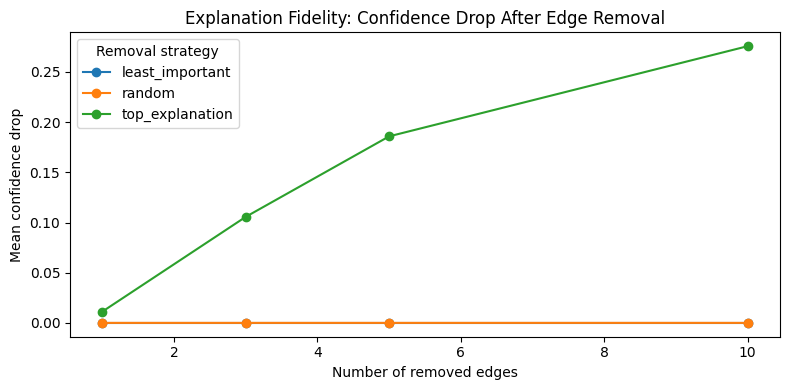

In [94]:
fig, ax = plt.subplots(figsize=(8, 4))

for strategy, group in fidelity_summary.groupby("removal_strategy"):
    ax.plot(
        group["removed_edges"],
        group["mean_confidence_drop"],
        marker="o",
        label=strategy,
    )

ax.set_title("Explanation Fidelity: Confidence Drop After Edge Removal")
ax.set_xlabel("Number of removed edges")
ax.set_ylabel("Mean confidence drop")
ax.legend(title="Removal strategy")

plt.tight_layout()
plt.show()

## 16. Batch Export Explanations

This optional section generates and saves GNNExplainer explanations for all correctly predicted test nodes. It is useful for downstream conversational explanation generation and aggregate evaluation.

#### 16.1 Configure Batch Export

In [95]:
RUN_BATCH_EXPORT = False  # set to True to run batch explanation export

batch_nodes_to_explain = test_predictions[test_predictions["correct"]].reset_index(
    drop=True
)

batch_node_ids = batch_nodes_to_explain["node_id"].astype(int).tolist()

print(f"Correctly predicted test nodes available: {len(batch_node_ids)}")

Correctly predicted test nodes available: 34


#### 16.2 Run Batch Export

In [96]:
batch_explanation_summaries = []

if RUN_BATCH_EXPORT:
    for batch_position, node_id in enumerate(batch_node_ids, start=1):

        # Retrieve the prediction corresponding to the current node
        selected_prediction = test_predictions[
            test_predictions["node_id"] == node_id
        ].iloc[0]

        print(f"[{batch_position}/{len(batch_node_ids)}] Explaining node {node_id}")

        # Generate a local explanation for the selected prediction
        explanation = explainer(
            x=data.x,
            edge_index=data.edge_index,
            edge_type=data.edge_type,
            index=node_id,
        )

        edge_mask = explanation.edge_mask.detach().cpu()
        explained_edge_index = explanation.edge_index.detach().cpu()
        explained_edge_type = explanation.edge_type.detach().cpu()

        # Select the highest-ranked explanation edges
        top_edge_indices = edge_mask.argsort(descending=True)[:EXPLAIN_TOP_K]

        explanation_edges = []
        explanation_edge_records = []

        # Convert the selected edges into RDF-style representations
        for edge_position in top_edge_indices.tolist():
            source_id = int(explained_edge_index[0, edge_position])
            target_id = int(explained_edge_index[1, edge_position])
            edge_type_id = int(explained_edge_type[edge_position])
            score = float(edge_mask[edge_position])

            explanation_edge_records.append(
                {
                    "source_id": source_id,
                    "target_id": target_id,
                    "edge_type": edge_type_id,
                    "importance": score,
                }
            )

            explanation_edges.append(
                edge_to_rdf_row(
                    source_id,
                    target_id,
                    edge_type_id,
                    score,
                )
            )

        # Create a ranked explanation table
        explanation_edges_df = (
            pd.DataFrame(explanation_edges)
            .sort_values("score", ascending=False)
            .reset_index(drop=True)
        )

        # Assemble the explanation record
        explanation_record = {
            "node_id": int(node_id),
            "node_uri": inv_nodes_dict[int(node_id)],
            "predicted_label_id": int(selected_prediction["pred_label_id"]),
            "predicted_label_uri": selected_prediction["pred_label_uri"],
            "true_label_id": int(selected_prediction["true_label_id"]),
            "true_label_uri": selected_prediction["true_label_uri"],
            "correct": bool(selected_prediction["correct"]),
            "edges": explanation_edge_records,
            "metadata": {
                "explainer": "GNNExplainer",
                "top_k_edges": len(explanation_edge_records),
                "edge_mask_type": "object",
                "excluded_predicates": [
                    str(predicate) for predicate in TARGET_PREDICATES_TO_EXCLUDE
                ],
            },
        }

        # Define output files
        explanation_json_path = EXPLANATIONS_DIR / f"gnnexplainer_node_{node_id}.json"

        explanation_edges_csv_path = (
            EXPLANATIONS_DIR / f"gnnexplainer_node_{node_id}_edges.csv"
        )

        # Save the explanation record
        explanation_json_path.write_text(
            json.dumps(
                explanation_record,
                indent=2,
            )
        )

        # Save the explanation edges in tabular form
        pd.DataFrame(explanation_edge_records).assign(
            node_id=int(node_id),
            node_uri=inv_nodes_dict[int(node_id)],
            predicted_label_id=int(selected_prediction["pred_label_id"]),
            predicted_label_uri=selected_prediction["pred_label_uri"],
            true_label_id=int(selected_prediction["true_label_id"]),
            true_label_uri=selected_prediction["true_label_uri"],
            correct=bool(selected_prediction["correct"]),
        ).to_csv(
            explanation_edges_csv_path,
            index=False,
        )

        # Store a compact summary for inspection
        batch_explanation_summaries.append(
            {
                "node_id": int(node_id),
                "node_uri": inv_nodes_dict[int(node_id)],
                "prediction_correct": bool(selected_prediction["correct"]),
                "top_predicates": ", ".join(
                    explanation_edges_df["rdf_predicate"].head(5).tolist()
                ),
                "json_path": explanation_json_path,
                "edges_csv_path": explanation_edges_csv_path,
            }
        )

else:
    print("Batch export skipped. Set RUN_BATCH_EXPORT = True to run it.")

Batch export skipped. Set RUN_BATCH_EXPORT = True to run it.


#### 16.3 Inspect Batch Export Summary

In [97]:
batch_explanation_summaries_df = pd.DataFrame(batch_explanation_summaries)

batch_explanation_summaries_df

""
